# Plume_MoM_TSM

PLUME-MoM-TSM is a new version of the integral model for volcanic plumes PLUME-MoM.

The model describes the steady-state dynamics of a plume in a 3-D coordinate system, and the two-size moment (TSM) method is adopted to describe changes in grain-size distribution along the plume associated with particle loss from plume margins and with particle aggregation. 

In [18]:
import sys
import subprocess
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline 

### We first must configure the base level or "control" parameters

In [2]:
run_name = "strong"
# Include the Dakota software framework, used for parameter estimation and UQ
dakota_flag = False
#flag for water condensation - freezing - addition of external liquid water at the vent
inversion_flag = False
# Run Hysplit on completion
hysplit_flag = False
# Enable particle aggregation
aggregation_flag = False
# flag for water condensation - freezing - addition of external liquid water at the vent
water_flag = False
# Flag to allow for entrainment above neutral buoyancy level
entr_flag = True
# flag to solve the model for the umbrella spreading
umbrella_flag = False

### Initial Values

In [3]:
# Initial vertical velocity of the plume
w0=  275.00000000000000
# Initial mass flow rate
mfr0 =   1.5E9
# Initial temperature
t_mix0 =  1053.00
# Set if density is initially neutral at the base
neutral_dens ='F'
# Initial water mass fraction
h20_mass_frac =  0.05
# Vent height
vent_height = 1500.00
# Initial intergation step
dz0 =  5.00
# Number of volcanic gas species
n_gas = 0

### Moment parameters

In [4]:
# Number of moments
n_mom = 2
# Number of nodes for the quadrature.
n_nodes = 5
# Number of sections
n_sections = 22
# Number of particle phases 
n_part = 2

### Particulate params

In [5]:
# Minimum particle size
phi_min = -6.0
# deviation of particle size
delta_phi =  1.
# Particle distribution method
distribution = "LOGNORMAL"
# Mass fraction of the particle phases with respect to the total solid 
solid_partial_mass_frac =  (0.5, 0.5)
# First diameter for the density function.
phi1 = (-1, -1)
# Density at phi1
rho1=  (2500, 2700)
# Second diameter for the density function.
phi2=  (4, 4)
# Density at phi2
rho2 =  (2500, 2700)
# Heat capacity of particle phases
cp_part = (1100, 1100)
# Shape factor for settling velocity (Pfeiffer)
shape_factor =  (0.6, 0.6)
# Boolean defining if we lse particles 
particles_loss=True
# Choose between two settling models: "textor" or "pfeiffer"
settling_model = "textor    "

### Entrainment params

In [6]:
# entrainment coefficient (parallel direction) 
alpha_inp =  8.9999999999999997E-002
# entrainment coefficient (normal direction) 
beta_inp = 0.59999999999999998

### Atmospheric params

In [7]:
# Atmospheric kinematic viscosity at sea level
visc_atm0 = 1e-5
# perfect gas constant for dry air ( J/(kg K) ) 
r_air = 287.02600097656250 
# specific heat capacity for dry air 
cp_air = 998.00000000000000
# Wind multiplication coefficient
wind_mult_coeff = 1

read_atm_profile = "card"

### Lognorm params

In [8]:
# The mean of the lognorm function
mu_lognormal = (1,6)
# The standard deviation of the lognorm function
sigma_lognormal = '2*1.6'

### The atmospheric data will require the following 7 parameters

1) height (km asl)
2) density (kg/m^3)
3) pressure (hPa)
4) temperature (K)
5) specific-humidity (kg/kg)
6) wind velocity West->East (m/s)
7) wind velocity North-South (m/s)

In [9]:
n_atm = 40

height = [0.1000000E+01, 0.1500000E+01, 0.2000000E+01, 0.3000000E+01, 0.4000000E+01, 0.5000000E+01, 0.6000000E+01, 0.7000000E+01, 0.8000000E+01, 0.9000000E+01, 0.1000000E+02, 0.1100000E+02, 0.1200000E+02, 0.1300000E+02, 0.1400000E+02, 0.1500000E+02, 0.1600000E+02, 0.1700000E+02, 0.1800000E+02, 0.1900000E+02, 0.2000000E+02, 0.2100000E+02, 0.2200000E+02, 0.2300000E+02, 0.2400000E+02, 0.2500000E+02, 0.2600000E+02, 0.2700000E+02, 0.2800000E+02, 0.2900000E+02, 0.3000000E+02, 0.3100000E+02, 0.3200000E+02, 0.3300000E+02, 0.3400000E+02, 0.3500000E+02, 0.3600000E+02, 0.3700000E+02, 0.3800000E+02, 0.3900000E+02]

density = [0.1061000E+01, 0.1011000E+01, 0.9620000E+00, 0.8670000E+00, 0.7830000E+00, 0.7050000E+00, 0.6330000E+00, 0.5690000E+00, 0.5110000E+00, 0.4590000E+00, 0.4120000E+00, 0.3690000E+00, 0.3310000E+00, 0.2950000E+00, 0.2600000E+00, 0.2290000E+00, 0.1990000E+00, 0.1690000E+00, 0.1390000E+00, 0.1140000E+00, 0.9500000E-01, 0.7900000E-01, 0.6800000E-01, 0.5700000E-01, 0.4700000E-01, 0.4100000E-01, 0.3400000E-01, 0.2900000E-01, 0.2600000E-01, 0.2200000E-01, 0.1900000E-01, 0.1500000E-01, 0.1300000E-01, 0.1100000E-01, 0.1000000E-01, 0.8000000E-02, 0.7000000E-02, 0.6000000E-02, 0.5000000E-02, 0.5000000E-02]

pressure = [0.8928100E+03, 0.8436340E+03, 0.7944570E+03, 0.7054780E+03, 0.6253910E+03, 0.5526070E+03, 0.4877400E+03, 0.4292070E+03, 0.3765980E+03, 0.3293770E+03, 0.2868910E+03, 0.2480990E+03, 0.2139750E+03, 0.1832830E+03, 0.1560480E+03, 0.1321720E+03, 0.1114470E+03, 0.9398600E+02, 0.7906100E+02, 0.6636500E+02, 0.5635200E+02, 0.4790500E+02, 0.4153200E+02, 0.3515800E+02, 0.2940900E+02, 0.2551200E+02, 0.2161500E+02, 0.1882700E+02, 0.1663000E+02, 0.1443400E+02, 0.1223700E+02, 0.1007900E+02, 0.8834000E+01, 0.7589000E+01, 0.6579000E+01, 0.5726000E+01, 0.4944000E+01, 0.4406000E+01, 0.3867000E+01, 0.3329000E+01]

temperature = [0.2931650E+03, 0.2904930E+03, 0.2878200E+03, 0.2834040E+03, 0.2782210E+03, 0.2732650E+03, 0.2685870E+03, 0.2630170E+03, 0.2569970E+03, 0.2501870E+03, 0.2425570E+03, 0.2342770E+03, 0.2251970E+03, 0.2165530E+03, 0.2087240E+03, 0.2009790E+03, 0.1948600E+03, 0.1938560E+03, 0.1976450E+03, 0.2019710E+03, 0.2069420E+03, 0.2106450E+03, 0.2126730E+03, 0.2147000E+03, 0.2168260E+03, 0.2192460E+03, 0.2216670E+03, 0.2236620E+03, 0.2254320E+03, 0.2272010E+03, 0.2289710E+03, 0.2307780E+03, 0.2334780E+03, 0.2361770E+03, 0.2394920E+03, 0.2432170E+03, 0.2466460E+03, 0.2490510E+03, 0.2514560E+03, 0.2538620E+03]

sph = [0.1501500E-01, 0.1349200E-01, 0.1196800E-01, 0.1017300E-01, 0.8573000E-01, 0.6453000E-02, 0.4938000E-02, 0.3802000E-02, 0.2822000E-02, 0.1856000E-02, 0.1062000E-02, 0.5370000E-03, 0.2320000E-03, 0.8900000E-04, 0.3800000E-04, 0.1600000E-04, 0.8000000E-05, 0.6000000E-05, 0.7000000E-05, 0.6000000E-05, 0.7000000E-05, 0.5000000E-05, 0.5000000E-05, 0.5000000E-05, 0.4000000E-05, 0.5000000E-05, 0.4000000E-05, 0.4000000E-05, 0.5000000E-05, 0.5000000E-05, 0.5000000E-05, 0.4000000E-05, 0.4000000E-05, 0.4000000E-05, 0.4000000E-05, 0.4000000E-05, 0.4000000E-05, 0.4000000E-05, 0.4000000E-05, 0.4000000E-05]

wind_ew = [-0.6904000E+01, -0.6252000E+01, -0.5600000E+01, -0.3669000E+01, -0.1170000E+00,  0.2285000E+01,  0.2669000E+01,  0.2682000E+01,  0.2667000E+01,  0.2942000E+01,  0.3373000E+01,  0.3738000E+01,  0.4396000E+01,  0.6826000E+01,  0.9737000E+01,  0.1207400E+02,  0.1360400E+02,  0.1169600E+02,  0.6810000E+01,  0.3912000E+01,  0.3085000E+01,  0.2983000E+01,  0.3595000E+01,  0.4207000E+01,  0.4859000E+01,  0.5633000E+01,  0.6406000E+01,  0.6981000E+01,  0.7450000E+01,  0.7919000E+01,  0.8388000E+01,  0.8859000E+01,  0.9361000E+01,  0.9864000E+01,  0.9844000E+01,  0.9476000E+01, 0.8986000E+01, 0.8077000E+01, 0.7167000E+01, 0.6257000E+01]

wind_ns = [-0.1013800E+02, -0.9703000E+01, -0.9268000E+01, -0.7450000E+01, -0.3535000E+01, -0.1350000E+00,  0.1164000E+01,  0.1984000E+01,  0.2875000E+01,  0.4106000E+01,  0.5575000E+01,  0.7087000E+01,  0.8868000E+01,  0.1140500E+02,  0.1333000E+02,  0.1453600E+02,  0.1548600E+02,  0.1354200E+02,  0.8976000E+01,  0.6277000E+01,  0.5521000E+01,  0.5671000E+01,  0.6626000E+01,  0.7581000E+01,  0.8589000E+01,  0.9758000E+01,  0.1092500E+02,  0.1182100E+02,  0.1257100E+02,  0.1332100E+02,  0.1407200E+02,  0.1482600E+02,  0.1568400E+02,  0.1654300E+02,  0.1664900E+02,  0.1625500E+02,  0.1575500E+02,  0.1489100E+02,  0.1402700E+02,  0.1316200E+02]

In [10]:
newline = '\n'
inp = f"""&CONTROL_PARAMETERS
 RUN_NAME="{run_name}",
 VERBOSE_LEVEL=         0,
 DAKOTA_FLAG={'T' if dakota_flag else 'F'},
 INVERSION_FLAG={'T' if inversion_flag else 'F'},
 HYSPLIT_FLAG={'T' if hysplit_flag else 'F'},
 AGGREGATION_FLAG={'T' if aggregation_flag else 'F'},
 WATER_FLAG={'T' if water_flag else 'F'},
 ENTR_ABV_NBL_FLAG={'T' if entr_flag else 'F'},
 UMBRELLA_FLAG={'T' if umbrella_flag else 'F'},
 /
&MOM_PARAMETERS
 N_PART=          {n_part},
 N_MOM=          {n_mom},
 N_NODES=          {n_nodes},
 N_SECTIONS=         {n_sections},
 /
&PARTICLES_PARAMETERS
 PHI_MIN= {phi_min},
 DELTA_PHI=  {delta_phi} ,
 DISTRIBUTION={distribution},
 SOLID_PARTIAL_MASS_FRACTION=  {solid_partial_mass_frac[0]}     ,{solid_partial_mass_frac[1]},
 PHI1= {phi1[0]}     ,{phi1[1]},
 RHO1=  {rho1[0]}     ,{rho1[1]},
 PHI2=  {phi2[0]}     ,{phi2[1]},
 RHO2=  {rho2[0]}     ,{rho2[1]},
 CP_PART=  {cp_part[0]}     ,{cp_part[1]},
 SHAPE_FACTOR=  {shape_factor[0]}     ,{shape_factor[1]},
 PARTICLES_LOSS={'T' if particles_loss else 'F'},
 SETTLING_MODEL="{settling_model}    ",
 /
&ENTRAINMENT_PARAMETERS
 ALPHA_INP=  {alpha_inp},
 BETA_INP= {beta_inp}    ,
 /
&ATM_PARAMETERS
 VISC_ATM0=  {visc_atm0},
 RAIR=  {r_air}     ,
 CPAIR=  {cp_air} ,
 WIND_MULT_COEFF=  {wind_mult_coeff}     ,
 READ_ATM_PROFILE="{read_atm_profile}  ",
 /
&INITIAL_VALUES
 W0=  {w0}     ,
 MFR0=   {mfr0},
 T_MIX0=  {t_mix0}     ,
 INITIAL_NEUTRAL_DENSITY={neutral_dens},
 WATER_MASS_FRACTION0= {h20_mass_frac},
 VENT_HEIGHT=  {vent_height}     ,
 DZ0=  {dz0}     ,
 N_GAS= {n_gas},
 /
&LOGNORMAL_PARAMETERS
 MU_LOGNORMAL=  {mu_lognormal[0]}   ,{mu_lognormal[1]},
 SIGMA_LOGNORMAL=  {sigma_lognormal}       ,
 /
 'ATM_PROFILE'
          40
{newline.join(f'  {height[i]}  {density[i]}  {pressure[i]}  {temperature[i]} {sph[i]} {wind_ew[i]} {wind_ns[i]}' for i in range(n_atm))}
"""

In [11]:
f = open("plumemom.inp",'w')
f.write(inp)
f.close()

subprocess.run("./PLUMEMoM plumemom.inp",shell=True)



 -------------------- PlumeMoM V.2 ---------------------

 Created by M.de' Michieli Vitturi(1) and F.Pardini (1)
 
 (1) Istituto Nazionale di Geofisica e Vulcanologia
     Sezione Pisa, Pisa, Italy

 search atm_profile
 LOG10 mass eruption rate =   9.1760912590556813     
 ---------- INITIALIZATION ------------

 SOLID PARTIAL MASS DISTRIBUTOINS
 Particle phase:           1
   -6.00   -5.00   -4.00   -3.00   -2.00   -1.00    0.00    1.00    2.00    3.00    4.00    5.00    6.00    7.00    8.00    9.00   10.00   11.00   12.00   13.00   14.00   15.00
   -5.00   -4.00   -3.00   -2.00   -1.00    0.00    1.00    2.00    3.00    4.00    5.00    6.00    7.00    8.00    9.00   10.00   11.00   12.00   13.00   14.00   15.00   16.00
 2.2E-04 1.9E-03 1.1E-02 4.3E-02 1.1E-01 2.1E-01 2.5E-01 2.1E-01 1.1E-01 4.3E-02 1.1E-02 1.9E-03 2.2E-04 1.7E-05 9.3E-07 3.4E-08 8.2E-10 1.4E-11 1.5E-13 1.2E-15 5.9E-18 2.0E-20

 Particle phase:           2
   -6.00   -5.00   -4.00   -3.00   -2.00   -1.00    0.00   

CompletedProcess(args='./PLUMEMoM plumemom.inp', returncode=0)

In [13]:
subprocess.run(f"sed -i 's/,$//' {run_name}_col.csv",shell=True)

CompletedProcess(args="sed -i 's/,$//' strong_col.csv", returncode=0)

aggregation_flag False
n_sections 22
phi_min -6.0
delta_phi 1.0
number of particles phases 2
number of bins  22
number of volcanic gases  0


/home/jovyan/PLUME-MoM/plot_plume.py:781: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  "t=" + "{:6.1f}".format(float(time_steps[0])) + 's',
/home/jovyan/PLUME-MoM/plot_plume.py:53: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  title.set_text("t=" + "{:6.1f}".format(float(time_steps[i])) + 's')


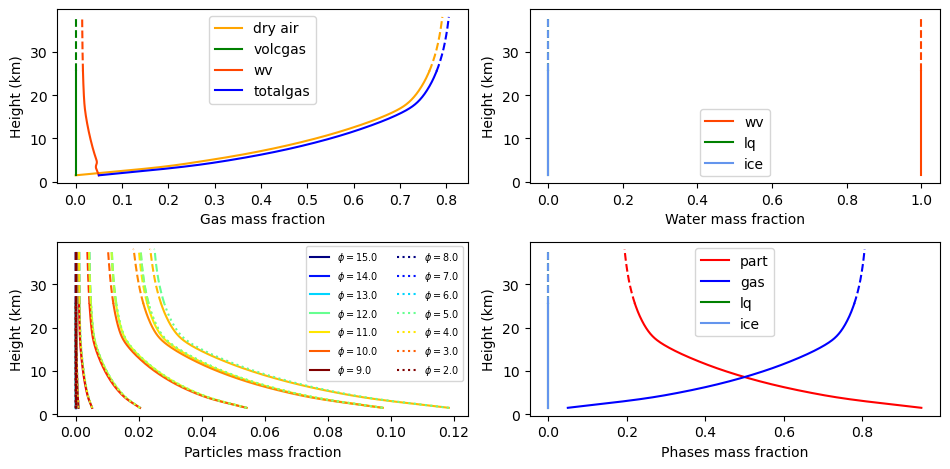

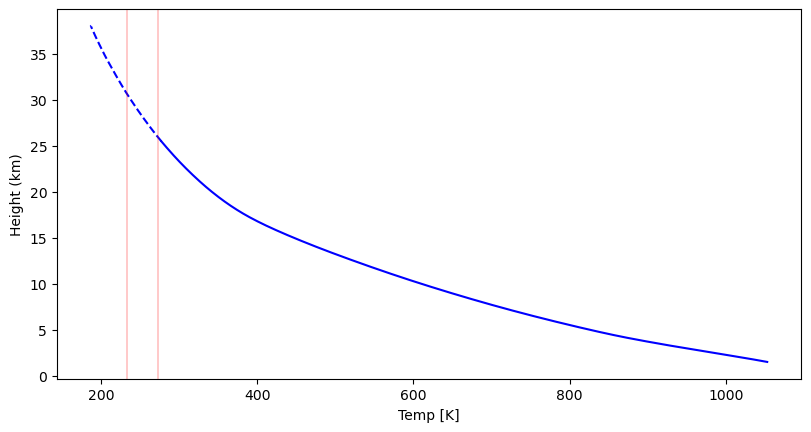

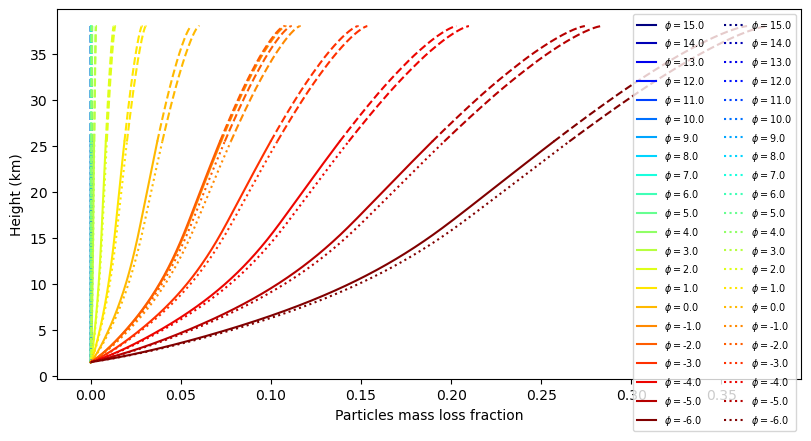

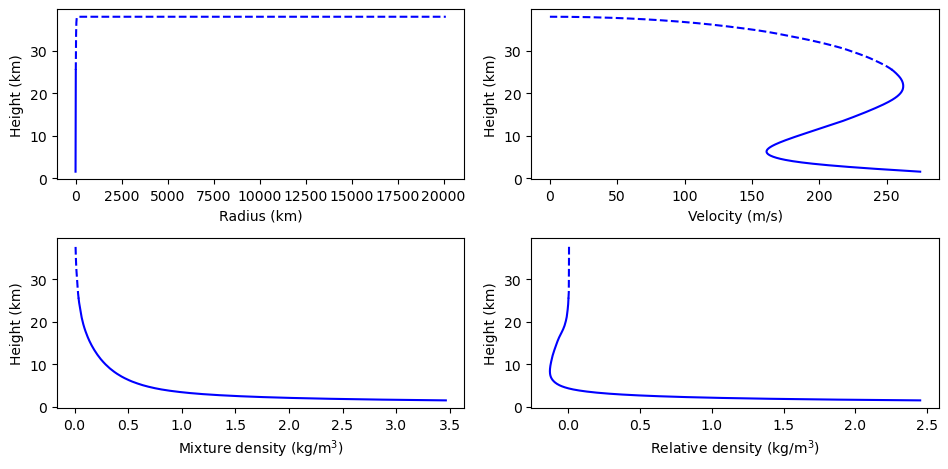

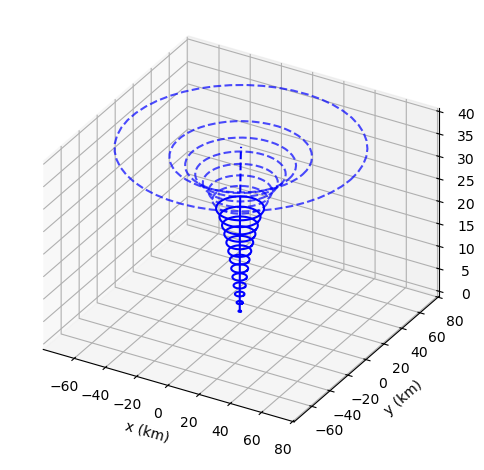

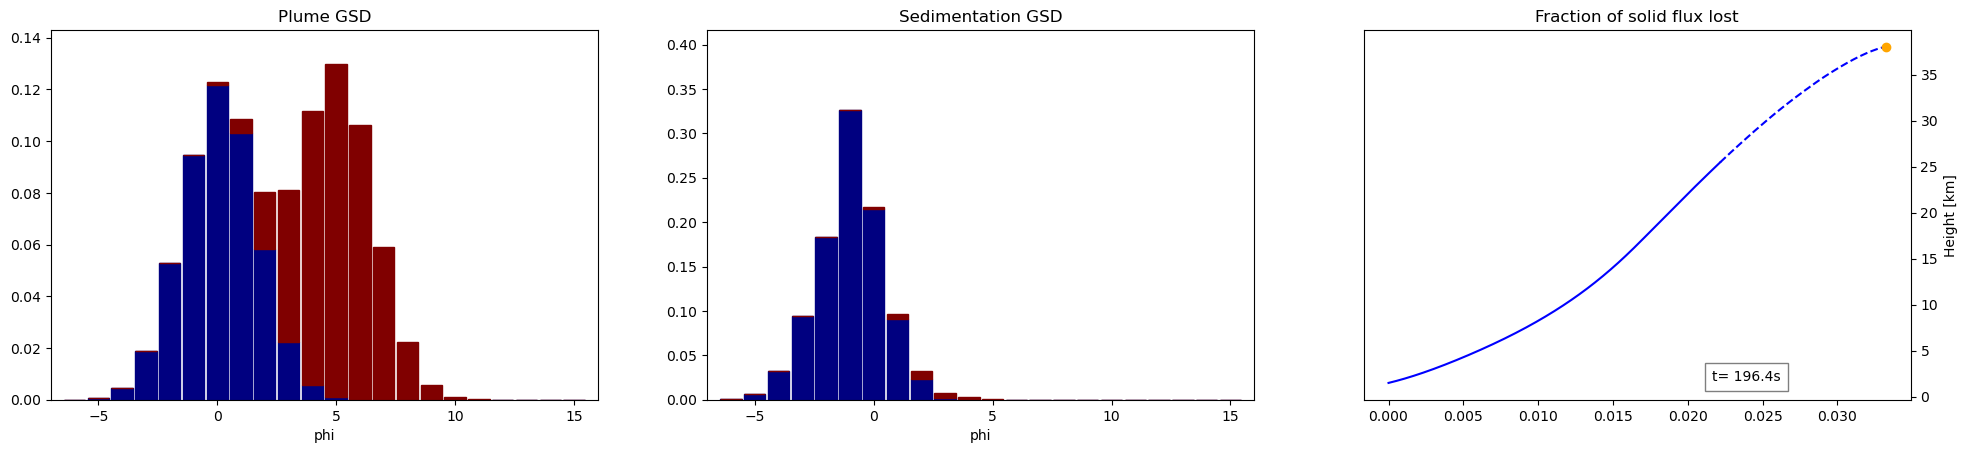

<Figure size 2400x480 with 0 Axes>

In [20]:
%run plot_plume.py -run strong